# Card-store pricing & restock optimizer

How to use: edit the settings cell, then **Run All**. Inputs you can edit live in `data/synthetic/inputs/`:
`restock_costs.csv` (your buy cost, min order, max units per product), `tcg_map.csv` (market-feed matches),
`catalog_overrides.csv` (fix a title the parser got wrong). Outputs go to `out/`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from milo import pipeline, demand, pricing
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)

# ---- settings ----
HORIZON_WEEKS = 8          # how far ahead to plan
LEAD_WEEKS = 1             # restock arrives after this many weeks
BUDGETS = [0, 1000, 2500, 5000, 10000]
MAIN_BUDGET = 5000         # the budget the buy list is built for
SEASON_UPLIFT = 1.3        # holiday scenario (1.0 / 1.3 / 1.6); not estimated from data (edge case D8)
SET_CAP_SHARE = 0.35       # max share of the budget in one set
N_SCENARIOS = 60           # demand scenarios for the main plan (a third each low/base/high price sensitivity)

out = pipeline.run(HORIZON_WEEKS, LEAD_WEEKS, BUDGETS, MAIN_BUDGET, SEASON_UPLIFT, N_SCENARIOS, SET_CAP_SHARE)

## 1. Data loaded

In [2]:
out["summary"]

,source,rows,units,from,to
0,store sales (seller_a),596,615.0,2026-07-06,2026-10-18
1,store sales (seller_b),208,208.0,2026-07-06,2026-10-18
2,market feed daily (from individual sales),427,911.0,2026-09-29,2026-10-20
3,market feed products pulled,22,NaN,2025-10-14,2026-10-20
4,Commission workbook lines,119,NaN,2026-09-28,2026-10-18


In [3]:
cat = out["data"]["catalog"]
print("Card fee share (paid by card):", round(out["data"]["card_share"], 3),
      "| units per order:", round(out["data"]["units_per_order"], 2))
cat[cat["needs_review"]][["product", "variant", "product_type", "set"]]

Card fee share (paid by card): 0.919 | units per order: 1.02


,product,variant,product_type,set


### Store demand by weekday
Whole-store orders per day estimated from order-number gaps (the store is closed one weekday).
The weekend share feeds the Friday shelf check in section 7.

In [4]:
out["weekday"][["weekday", "full_days", "avg_store_orders", "share_of_week"]].round(3)

,weekday,full_days,avg_store_orders,share_of_week
0,Mon,14,41.2,0.122
1,Tue,15,43.7,0.130
2,Wed,15,6.9,0.000
3,Thu,15,46.4,0.138
4,Fri,15,66.8,0.198
5,Sat,15,76.5,0.227
6,Sun,14,62.6,0.186


### Restock timing (copied as-is from the store's reporting)
Shelf rule used for in-stock days: an upload entered after hours sells from the **next open day**, edits during
store hours sell the same day, and the store is closed one weekday. Bulk orders (15+ units of an item in one
order, or one order that is most of an item's sales) are left out of demand rates but still leave the shelf.

In [5]:
rt = out["restock_tables"]
print("Best sellers that sat sold out (est. missed sales):")
display(rt.get("sold_out", pd.DataFrame()).head(15))
print("Items selling 0.5+/day: days of cover:")
display(rt.get("restock_soon", pd.DataFrame()))
print("Products both sellers carry:")
rt.get("shared_products", pd.DataFrame())

Best sellers that sat sold out (est. missed sales):


,Vendor,Product,Variant,SKU,Price,Sold,Days in stock,Steady days,Steady sale days,Bulk units left out,Days out,Sold per steady day,Other vendor units while out,Other vendor $ while out,Days store had none,Est missed units,Est missed $,Out now
0,Seller A,Game A Booster Pack (Seller A),Shadow Summit,SKU-0101,6.5,229,89,89,209,20,16,2.14,0,0.0,16,34.2,222.3,no
1,Seller A,Game A Booster Pack (Seller A),Ember Crown,SKU-0102,6.0,60,90,90,60,0,14,0.82,0,0.0,14,11.5,69.0,no
2,Seller A,Game A Booster Pack (Seller A),Crystal Tide,SKU-0103,5.5,63,83,83,63,0,20,0.79,0,0.0,20,15.8,86.9,no
3,Seller A,Game A Elite Trainer Box (Seller A) (ETB),Shadow Summit,SKU-0104,60.0,40,64,64,40,0,41,0.31,0,0.0,41,12.7,762.0,no
4,Seller A,Game A Elite Trainer Box (Seller A) (ETB),Ember Crown,SKU-0105,55.0,10,94,94,10,0,10,0.11,0,0.0,10,1.1,60.5,no
5,Seller A,Booster Bundle (Crystal Tide) · Sealed (Seller A),Default Title,SKU-0106,32.0,12,83,83,12,0,20,0.14,0,0.0,20,2.8,89.6,no
6,Seller A,Booster Box (Shadow Summit) · Sealed (Seller A),Default Title,SKU-0107,165.0,10,87,87,10,0,18,0.16,0,0.0,18,2.9,478.5,no
7,Seller A,Mini Tin (Lunar Bloom) · Sealed (Seller A),Default Title,SKU-0108,12.0,15,57,57,15,0,6,0.31,0,0.0,6,1.9,22.8,no
8,Seller A,Poster Collection (Ember Crown) · Sealed (Seller A),Default Title,SKU-0109,42.0,7,96,96,7,0,7,0.14,0,0.0,7,1.0,42.0,no
9,Seller A,Emberfox 026/128 · SS01: Shadow Summit · NM (Seller A),Near Mint,SKU-0133,12.0,16,78,78,16,0,27,0.17,0,0.0,27,4.6,55.2,no


Items selling 0.5+/day: days of cover:


,Vendor,Product,Variant,SKU,On shelf now,Arriving,Lands,Sold per in-stock day,In-stock days,Sale days,Bulk units left out,Days of cover,Days of cover with arriving
0,Seller A,Game A Booster Pack (Seller A),Shadow Summit,SKU-0101,15,0,NaN,2.14,89,209,20,7.0,7.0
1,Seller A,Game A Booster Pack (Seller A),Crystal Tide,SKU-0103,9,0,NaN,0.79,83,63,0,11.4,11.4
2,Seller A,Booster Bundle (Crystal Tide) · Sealed (Seller A),Default Title,SKU-0106,1,0,NaN,0.14,83,12,0,7.1,7.1
3,Seller A,Poster Collection (Ember Crown) · Sealed (Seller A),Default Title,SKU-0109,1,0,NaN,0.14,96,7,0,7.1,7.1
4,Seller A,Duskmaw 066/094 · NM (Seller A),Near Mint,SKU-0136,2,0,NaN,0.09,91,10,0,22.2,22.2
5,Seller A,Collector Crate (Shadow Summit) · Sealed (Seller A),Default Title,SKU-0138,2,0,NaN,0.12,88,8,0,16.7,16.7
6,Seller A,Clip-On Plushie Charm (3.5 in) (Seller A),New,SKU-0139,3,0,NaN,0.26,81,21,0,11.5,11.5
7,Seller A,Tidalon (Illustration Rare) 232/217 · Graded 10 (Seller A),Graded 10,SKU-0140,3,0,NaN,0.03,63,1,0,100.0,100.0
8,Seller A,Mirevyn 051/207 · Crystal Tide · NM (Seller A),Near Mint,SKU-200,5,0,NaN,0.38,89,31,0,13.2,13.2


Products both sellers carry:


,Type,Set,Seller A prices,Seller B prices,Seller A sold,Seller B sold,Days Seller A in stock,Days Seller B in stock,Days both out
0,booster_pack,Shadow Summit,NaN,NaN,NaN,NaN,NaN,NaN,0
1,etb,Shadow Summit,NaN,NaN,NaN,NaN,NaN,NaN,0


## 2. Baseline demand: P1 (in-stock rate) → P2 (shrunk toward type average)

In [6]:
p = out["p1p2"].sort_values("units", ascending=False)
p[["family", "product_type", "units", "in_stock_days", "raw_rate", "shrunk_rate", "p10", "p50", "p90", "flag"]].head(30).round(2)

,family,product_type,units,in_stock_days,raw_rate,shrunk_rate,p10,p50,p90,flag
4,seller_a|game_a|booster_pack|shadow summit,booster_pack,209.0,81,18.06,17.85,16.30,17.82,19.43,
19,seller_b|game_a|booster_pack|shadow summit,booster_pack,156.0,75,14.56,14.45,13.00,14.42,15.93,
2,seller_a|game_a|booster_pack|crystal tide,booster_pack,63.0,74,5.96,6.13,5.19,6.10,7.10,
11,seller_a|single|game_a|crystal tide|<5,single,61.0,90,4.74,4.49,3.79,4.47,5.23,
3,seller_a|game_a|booster_pack|ember crown,booster_pack,60.0,79,5.32,5.49,4.63,5.47,6.39,
8,seller_a|game_a|etb|shadow summit,etb,40.0,60,4.67,4.41,3.57,4.38,5.29,
20,seller_b|game_a|etb|shadow summit,etb,28.0,72,2.72,2.70,2.10,2.68,3.34,
16,seller_a|single|game_a|shadow summit|5-20,single,16.0,70,1.60,1.64,1.18,1.61,2.15,
14,seller_a|single|game_a|lunar bloom|20+,single,16.0,75,1.49,1.54,1.11,1.52,2.02,
10,seller_a|game_a|tin|lunar bloom,tin,15.0,49,2.14,1.95,1.41,1.92,2.55,


## 3. Online (market feed) vs in-person (the store)

In [7]:
out["online"]["by_type"].round(3)

,product_type,products,store_units,online_units,median_premium,p25_premium,p75_premium,median_capture,pooled_capture
0,booster_box,2,24.0,84.810,1.208,1.165,1.251,0.312,0.283
1,booster_bundle,2,22.0,70.333,1.153,1.127,1.178,0.328,0.313
2,booster_pack,4,488.0,1454.905,1.334,1.304,1.357,0.260,0.335
3,collection,2,15.0,72.952,1.292,1.250,1.335,0.242,0.206
4,etb,3,78.0,183.762,1.230,1.146,1.231,0.503,0.424
5,single,7,129.0,629.286,1.230,1.142,1.279,0.228,0.205
6,tin,2,25.0,108.619,1.245,1.241,1.250,0.295,0.230


In [8]:
cols = ["product", "seller", "product_type", "in_stock_days", "store_units", "online_units", "our_price", "online_price", "premium", "capture_rate"]
out["online"]["products"].sort_values("store_units", ascending=False)[cols].head(30).round(3)

,product,seller,product_type,in_stock_days,store_units,online_units,our_price,online_price,premium,capture_rate
11,Game A Booster Pack (Seller A),seller_a,booster_pack,81,209.0,380.238,6.50,5.110,1.272,0.550
3,Booster Pack - Shadow Summit (Seller B),seller_b,booster_pack,75,156.0,586.762,7.00,5.130,1.365,0.266
9,Game A Booster Pack (Seller A),seller_a,booster_pack,74,63.0,251.857,5.50,4.185,1.314,0.250
10,Game A Booster Pack (Seller A),seller_a,booster_pack,79,60.0,236.048,6.00,4.430,1.354,0.254
13,Game A Elite Trainer Box (Seller A) (ETB),seller_a,etb,60,40.0,67.286,60.00,56.500,1.062,0.594
16,Mirevyn 051/207 · Crystal Tide · NM (Seller A),seller_a,single,79,31.0,136.238,4.60,3.530,1.303,0.228
8,Galeheart 004/102 · Crystal Tide · LP (Seller A),seller_a,single,69,30.0,211.429,4.00,3.440,1.163,0.142
6,ETB - Shadow Summit (Seller B),seller_b,etb,72,28.0,55.619,62.00,50.400,1.230,0.503
17,Pebblit 046/139 · Lunar Bloom · NM (Seller A),seller_a,single,75,16.0,80.762,36.70,26.790,1.370,0.198
7,Emberfox 026/128 · SS01: Shadow Summit · NM (Seller A),seller_a,single,70,16.0,94.143,12.00,9.760,1.230,0.170


In [9]:
print("Does online demand show up in the store 0/1/2 weeks later? (pooled within-product correlation)")
out["online"]["lags"].round(3)

Does online demand show up in the store 0/1/2 weeks later? (pooled within-product correlation)


,lag_weeks,corr,pairs
0,0,-0.033,276
1,1,0.000,254
2,2,-0.040,232


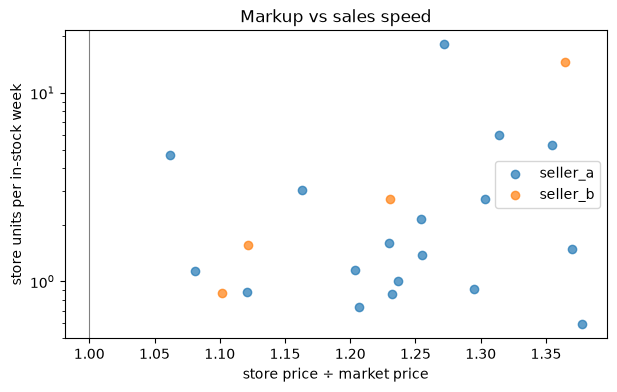

In [10]:
prod = out["online"]["products"].dropna(subset=["premium"])
fig, ax = plt.subplots(figsize=(7, 4))
for seller, part in prod.groupby("seller"):
    ax.scatter(part["premium"], part["store_per_week"], label=seller, alpha=0.7)
ax.set_xlabel("store price ÷ market price"); ax.set_ylabel("store units per in-stock week")
ax.set_yscale("log"); ax.axvline(1.0, color="grey", lw=0.8); ax.legend(); ax.set_title("Markup vs sales speed")
plt.show()

## 4. Backtest: fit before the split date, predict after it

In [11]:
joined, by_type = out["backtest_plain"]
joined_t, by_type_t = out["backtest_traffic"]
print("Totals without traffic step:", by_type[["actual", "pred_shrunk", "pred_raw"]].sum().round(1).to_dict())
print("Totals with traffic step:   ", by_type_t[["actual", "pred_shrunk", "pred_raw"]].sum().round(1).to_dict())
by_type_t.round(2)

Totals without traffic step: {'actual': 154.0, 'pred_shrunk': 149.9, 'pred_raw': 150.3}
Totals with traffic step:    {'actual': 154.0, 'pred_shrunk': 148.5, 'pred_raw': 148.8}


,product_type,families,actual,pred_shrunk,pred_raw,mae_shrunk,mae_raw
0,booster_box,2,5.0,3.73,3.79,0.91,1.12
1,booster_bundle,2,7.0,3.62,3.65,1.69,1.67
2,booster_pack,4,93.0,93.97,93.93,1.38,1.05
3,collection,2,4.0,2.44,2.48,1.27,1.44
4,etb,3,17.0,14.10,14.04,1.47,1.14
5,single,6,21.0,24.76,24.78,1.50,1.71
6,tin,2,7.0,5.83,6.17,0.58,0.41


## 5. Price response: P4 position vs market → P5 sensitivity → P6 curve

In [12]:
print(out["sensitivity"]["fe_info"])
out["sensitivity"]["elasticities"].round(3)

    group  units  units_with_price_movement  product_days
0  sealed     15                         15          1096
1  single      7                          7           518


,group,side,low,base,high,source,note
0,sealed,below,-2.625,-2.625,-2.625,own sales vs daily market price (fixed effects),envelope clip binding
1,sealed,above,-2.625,-2.625,-3.500,assumed range,fixed-effects fit rejected (sign or interval crosses 0);...
2,single,below,-0.250,-0.600,-1.250,assumed range,fixed-effects fit rejected (sign or interval crosses 0);...
3,single,above,-0.500,-1.200,-2.500,assumed range,fixed-effects fit rejected (sign or interval crosses 0);...


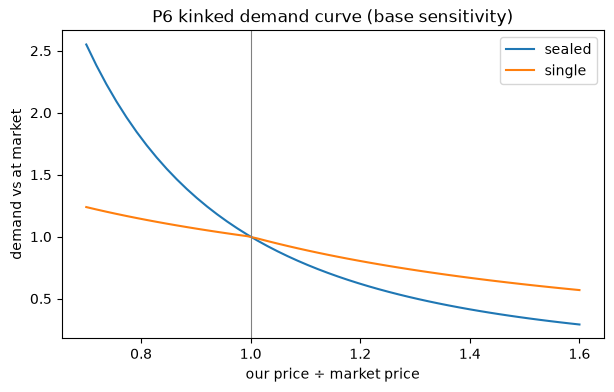

In [13]:
el = out["sensitivity"]["elasticities"]
m = np.linspace(0.7, 1.6, 50)
fig, ax = plt.subplots(figsize=(7, 4))
for group in ["sealed", "single"]:
    below = el[(el.group == group) & (el.side == "below")].iloc[0]["base"]
    above = el[(el.group == group) & (el.side == "above")].iloc[0]["base"]
    ax.plot(m, pricing.h(m, below, above), label=group)
ax.axvline(1.0, color="grey", lw=0.8); ax.set_xlabel("our price ÷ market price"); ax.set_ylabel("demand vs at market")
ax.legend(); ax.set_title("P6 kinked demand curve (base sensitivity)"); plt.show()

In [14]:
d = out["demand"]
print("P7 check: demand never rises with price in any scenario:", bool(np.all(np.diff(d, axis=1) <= 0)))

P7 check: demand never rises with price in any scenario: True


## 6. Restock units and inputs

In [15]:
print("shared_with_other_seller = another seller carries it too; demand there rises when they are out (v1 assumes independent demand).")
out["units"][["unit", "product_type", "price_now", "market_price", "cost", "cost_source", "on_hand", "shrunk_rate",
              "shared_with_other_seller", "data_flag"]].round(2)

shared_with_other_seller = another seller carries it too; demand there rises when they are out (v1 assumes independent demand).


,unit,product_type,price_now,market_price,cost,cost_source,on_hand,shrunk_rate,shared_with_other_seller,data_flag
0,seller_a|game_a|booster_box|shadow summit,booster_box,165.00,127.46,109.20,restock_costs.csv,0.0,0.98,False,
1,seller_a|game_a|booster_bundle|crystal tide,booster_bundle,32.00,26.58,18.10,unit cost sheet,1.0,1.11,False,
2,seller_a|game_a|booster_pack|crystal tide,booster_pack,5.50,4.19,2.93,unit cost sheet,9.0,6.13,False,
3,seller_a|game_a|booster_pack|ember crown,booster_pack,6.00,4.43,3.00,unit cost sheet,0.0,5.49,False,
4,seller_a|game_a|booster_pack|shadow summit,booster_pack,6.50,5.11,3.38,unit cost sheet,15.0,17.85,True,
5,seller_a|game_a|collection|ember crown,collection,42.00,30.48,19.96,unit cost sheet,1.0,0.61,False,
6,seller_a|game_a|collection|shadow summit,collection,48.00,39.77,24.69,unit cost sheet,2.0,0.70,False,
7,seller_a|game_a|etb|ember crown,etb,55.00,44.66,30.44,unit cost sheet,0.0,1.01,False,
8,seller_a|game_a|etb|shadow summit,etb,60.00,56.50,33.43,unit cost sheet,0.0,4.41,True,
9,seller_a|game_a|tin|iron verdict,tin,43.47,35.16,26.37,default 75% of market price,0.0,1.10,False,


## 7. Optimal buy list and prices (Pyomo GDP → hull MILP, HiGHS)

In [16]:
plan = out["plan"]
print("status:", plan["status"], "| termination:", plan["termination"], "| optimal:", plan["optimal"],
      "| gap:", plan["mip_gap"], "| expected profit:", round(plan["objective"], 2),
      "| LP relaxation:", round(plan["lp_relaxation_objective"], 2))
buy = plan["buy"].merge(plan["prices"], on="i", how="left")
buy[buy["units"] > 0].sort_values("spend", ascending=False).round(2)

status: optimal | termination: convergenceCriteriaSatisfied | optimal: True | gap: 0.0046760856924654625 | expected profit: 2250.44 | LP relaxation: 2263.42


,i,units,spend,level,ratio,price
8,seller_a|game_a|etb|shadow summit,24,802.32,7,1.15,69.00
0,seller_a|game_a|booster_box|shadow summit,6,655.20,7,1.15,189.75
7,seller_a|game_a|etb|ember crown,12,365.28,5,1.05,57.75
9,seller_a|game_a|tin|iron verdict,9,237.33,7,1.15,49.99
14,seller_a|single|game_a|lunar bloom|20+,13,220.35,7,1.15,42.20
5,seller_a|game_a|collection|ember crown,10,199.60,2,0.90,37.80
1,seller_a|game_a|booster_bundle|crystal tide,11,199.10,5,1.05,33.60
10,seller_a|game_a|tin|lunar bloom,17,122.02,5,1.05,12.60
16,seller_a|single|game_a|shadow summit|5-20,17,107.10,7,1.15,13.80
12,seller_a|single|game_a|ember crown|5-20,11,103.18,7,1.15,20.70


In [17]:
print("Flags by code (M1 dropped price levels, M2/M3 price at grid edge, M5 lumpiness, M10 not proven optimal):")
print(plan["flags"]["code"].value_counts())
print("\nProducts priced at the top level, and why:")
out["edge_reasons"]

Flags by code (M1 dropped price levels, M2/M3 price at grid edge, M5 lumpiness, M10 not proven optimal):
code
M2    13
M5     1
Name: count, dtype: int64

Products priced at the top level, and why:


,unit,stock,median_demand_at_top_price,reason
0,seller_a|game_a|booster_box|shadow summit,6.0,7.0,scarce: median demand at the top price still exceeds stock
1,seller_a|game_a|booster_pack|crystal tide,33.0,42.5,scarce: median demand at the top price still exceeds stock
2,seller_a|game_a|booster_pack|ember crown,24.0,41.0,scarce: median demand at the top price still exceeds stock
3,seller_a|game_a|booster_pack|shadow summit,39.0,139.5,scarce: median demand at the top price still exceeds stock
4,seller_a|game_a|collection|shadow summit,6.0,5.0,low price sensitivity: revenue still rises at the top price
5,seller_a|game_a|etb|shadow summit,24.0,25.0,scarce: median demand at the top price still exceeds stock
6,seller_a|game_a|tin|iron verdict,9.0,6.0,low price sensitivity: revenue still rises at the top price
7,seller_a|single|game_a|crystal tide|<5,29.0,44.5,scarce: median demand at the top price still exceeds stock
8,seller_a|single|game_a|ember crown|5-20,11.0,9.0,low price sensitivity: revenue still rises at the top price
9,seller_a|single|game_a|iron verdict|5-20,11.0,9.0,low price sensitivity: revenue still rises at the top price


In [18]:
print("Fri-Sun share of an open week:", round(out["weekend_share"], 3))
out["weekend"].head(25).round(2)

Fri-Sun share of an open week: 0.611


,unit,stock_after_buy,weekly_forecast,weekend_mean,friday_shelf_target_p90,weekends_covered,flag
4,seller_a|game_a|booster_pack|shadow summit,39.0,25.95,15.85,21.0,2.46,
3,seller_a|game_a|booster_pack|ember crown,24.0,8.48,5.18,8.0,4.63,
2,seller_a|game_a|booster_pack|crystal tide,33.0,7.60,4.64,7.0,7.11,
11,seller_a|single|game_a|crystal tide|<5,29.0,6.55,4.00,7.0,7.25,
8,seller_a|game_a|etb|shadow summit,24.0,5.55,3.39,6.0,7.08,
15,seller_a|single|game_a|lunar bloom|5-20,17.0,2.92,1.78,4.0,9.54,
16,seller_a|single|game_a|shadow summit|5-20,17.0,2.83,1.73,3.0,9.84,
10,seller_a|game_a|tin|lunar bloom,17.0,2.56,1.56,3.0,10.88,
14,seller_a|single|game_a|lunar bloom|20+,13.0,1.82,1.11,3.0,11.70,
0,seller_a|game_a|booster_box|shadow summit,6.0,1.55,0.95,2.0,6.33,


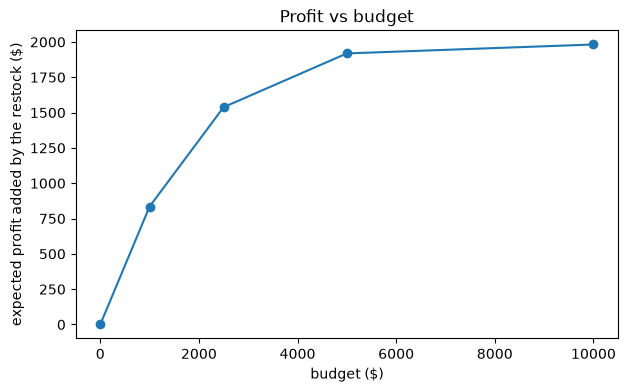

,budget,objective,spend,profit_from_restock,return_per_dollar
0,0,345.79,0.00,0.00,NaN
1,1000,1180.79,998.77,835.00,0.84
2,2500,1883.97,2494.40,1538.18,0.62
3,5000,2264.67,3523.27,1918.88,0.54
4,10000,2327.83,3992.48,1982.04,0.50


In [19]:
curve = out["budget_curve"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curve["budget"], curve["profit_from_restock"], marker="o")
ax.set_xlabel("budget ($)"); ax.set_ylabel("expected profit added by the restock ($)"); ax.set_title("Profit vs budget"); plt.show()
curve.round(2)

## 8. Pricing strategies on the same demand scenarios

In [20]:
out["strategies"].round(2)

,strategy,expected,p10,p50,p90,sell_through,leftover_value
0,keep,1857.24,1710.75,1876.35,1967.21,0.92,323.98
1,match_market,1217.41,1144.72,1225.94,1266.91,0.98,75.11
2,market_minus_5,1125.56,1064.44,1130.99,1173.47,0.98,68.89
3,market_plus_10,1552.97,1467.51,1554.05,1625.66,0.96,137.56
4,optimal (Pyomo),2250.44,1930.34,2264.12,2492.06,0.88,525.02


In [21]:
files = pipeline.export(out)
for path in files:
    print(path.relative_to(pipeline.PROJECT))

out/restock_plan.xlsx
out/online_vs_inperson.xlsx
